In [3]:
print("Welcome to Bank Customer Churn Prediction!")
print("My first Machine Learning project")
print("Python environment is ready!")

Welcome to Bank Customer Churn Prediction!
My first Machine Learning project
Python environment is ready!


In [4]:
import numpy as np
import pandas as pd

import matplotlib.pyplot as plt
import seaborn as sns

from pathlib import Path

print("All libraries imported successfully!")

All libraries imported successfully!


In [5]:
DATA_PATH = Path("../dataset/Churn_Modelling.csv")

df = pd.read_csv(DATA_PATH)

print("Dataset loaded successfully!")


Dataset loaded successfully!


In [6]:
df.head()


,RowNumber,CustomerId,Surname,CreditScore,Geography,Gender,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
0,1,15634602,Hargrave,619,France,Female,42,2,0.00,1,1,1,101348.88,1
1,2,15647311,Hill,608,Spain,Female,41,1,83807.86,1,0,1,112542.58,0
2,3,15619304,Onio,502,France,Female,42,8,159660.80,3,1,0,113931.57,1
3,4,15701354,Boni,699,France,Female,39,1,0.00,2,0,0,93826.63,0
4,5,15737888,Mitchell,850,Spain,Female,43,2,125510.82,1,1,1,79084.10,0


In [7]:
print("Rows:", df.shape[0])
print("Columns:", df.shape[1])


Rows: 10000
Columns: 14


In [8]:
# Display all column names

print("Dataset Columns:")
for column in df.columns:
    print(column)
    

Dataset Columns:
RowNumber
CustomerId
Surname
CreditScore
Geography
Gender
Age
Tenure
Balance
NumOfProducts
HasCrCard
IsActiveMember
EstimatedSalary
Exited


In [9]:
print("Number of rows:", df.shape[0])
print("Number of columns:", df.shape[1])


Number of rows: 10000
Number of columns: 14


In [10]:
df.info()


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 14 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   RowNumber        10000 non-null  int64  
 1   CustomerId       10000 non-null  int64  
 2   Surname          10000 non-null  object 
 3   CreditScore      10000 non-null  int64  
 4   Geography        10000 non-null  object 
 5   Gender           10000 non-null  object 
 6   Age              10000 non-null  int64  
 7   Tenure           10000 non-null  int64  
 8   Balance          10000 non-null  float64
 9   NumOfProducts    10000 non-null  int64  
 10  HasCrCard        10000 non-null  int64  
 11  IsActiveMember   10000 non-null  int64  
 12  EstimatedSalary  10000 non-null  float64
 13  Exited           10000 non-null  int64  
dtypes: float64(2), int64(9), object(3)
memory usage: 1.1+ MB


In [11]:
df.describe()


,RowNumber,CustomerId,CreditScore,Age,Tenure,Balance,NumOfProducts,HasCrCard,IsActiveMember,EstimatedSalary,Exited
count,10000.00000,1.000000e+04,10000.000000,10000.000000,10000.000000,10000.000000,10000.000000,10000.00000,10000.000000,10000.000000,10000.000000
mean,5000.50000,1.569094e+07,650.528800,38.921800,5.012800,76485.889288,1.530200,0.70550,0.515100,100090.239881,0.203700
std,2886.89568,7.193619e+04,96.653299,10.487806,2.892174,62397.405202,0.581654,0.45584,0.499797,57510.492818,0.402769
min,1.00000,1.556570e+07,350.000000,18.000000,0.000000,0.000000,1.000000,0.00000,0.000000,11.580000,0.000000
25%,2500.75000,1.562853e+07,584.000000,32.000000,3.000000,0.000000,1.000000,0.00000,0.000000,51002.110000,0.000000
50%,5000.50000,1.569074e+07,652.000000,37.000000,5.000000,97198.540000,1.000000,1.00000,1.000000,100193.915000,0.000000
75%,7500.25000,1.575323e+07,718.000000,44.000000,7.000000,127644.240000,2.000000,1.00000,1.000000,149388.247500,0.000000
max,10000.00000,1.581569e+07,850.000000,92.000000,10.000000,250898.090000,4.000000,1.00000,1.000000,199992.480000,1.000000


In [12]:
df.isnull().sum()

RowNumber          0
CustomerId         0
Surname            0
CreditScore        0
Geography          0
Gender             0
Age                0
Tenure             0
Balance            0
NumOfProducts      0
HasCrCard          0
IsActiveMember     0
EstimatedSalary    0
Exited             0
dtype: int64

In [13]:
print("Total duplicate rows:", df.duplicated().sum())

Total duplicate rows: 0


In [14]:
# Count customers who stayed and exited

churn_counts = df["Exited"].value_counts()

print("Customer Churn Distribution:")
print(churn_counts)

Customer Churn Distribution:
Exited
0    7963
1    2037
Name: count, dtype: int64


In [15]:
churn_percentage = df["Exited"].value_counts(normalize=True) * 100

print("Customer Churn Percentage:")
print(churn_percentage)

Customer Churn Percentage:
Exited
0    79.63
1    20.37
Name: proportion, dtype: float64


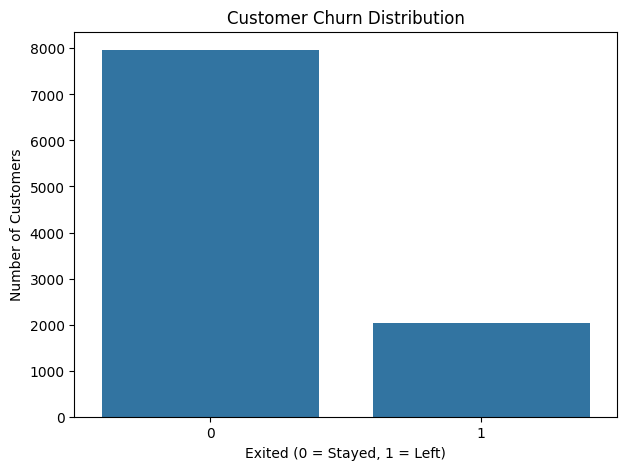

In [16]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Exited")

plt.title("Customer Churn Distribution")
plt.xlabel("Exited (0 = Stayed, 1 = Left)")
plt.ylabel("Number of Customers")

plt.show()

In [17]:
# Basic age statistics

print("Minimum Age:", df["Age"].min())
print("Maximum Age:", df["Age"].max())
print("Average Age:", df["Age"].mean())
print("Median Age:", df["Age"].median())

Minimum Age: 18
Maximum Age: 92
Average Age: 38.9218
Median Age: 37.0


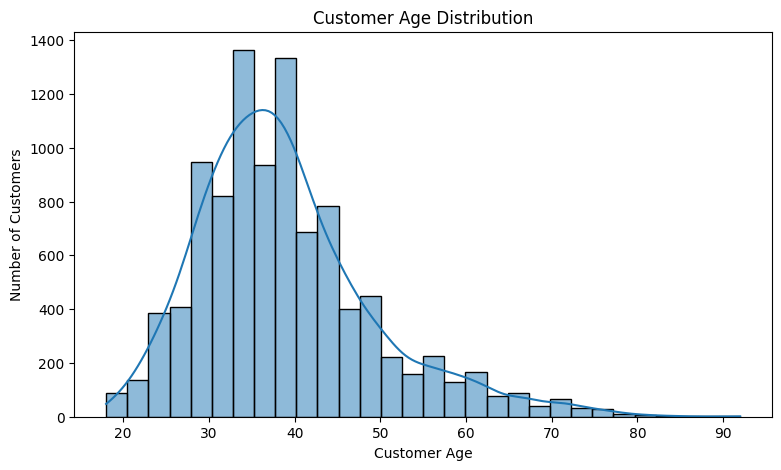

In [18]:
plt.figure(figsize=(9, 5))

sns.histplot(
    data=df,
    x="Age",
    bins=30,
    kde=True
)

plt.title("Customer Age Distribution")
plt.xlabel("Customer Age")
plt.ylabel("Number of Customers")

plt.show()

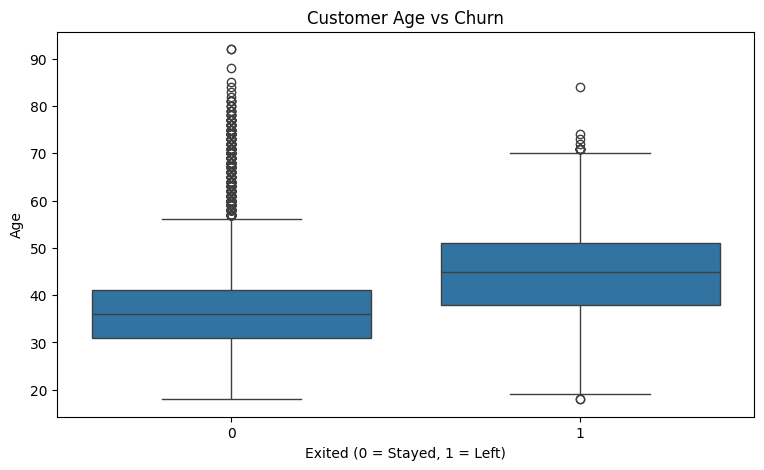

In [19]:
plt.figure(figsize=(9, 5))

sns.boxplot(
    data=df,
    x="Exited",
    y="Age"
)

plt.title("Customer Age vs Churn")
plt.xlabel("Exited (0 = Stayed, 1 = Left)")
plt.ylabel("Age")

plt.show()

In [20]:
# Create age groups for analysis
age_groups = pd.cut(
    df["Age"],
    bins=[0, 25, 35, 45, 55, 100],
    labels=["18-25", "26-35", "36-45", "46-55", "56+"]
)

# Calculate churn rate for each age group
age_churn = df.groupby(
    age_groups,
    observed=False
)["Exited"].mean() * 100

print("Churn Rate by Age Group:")
print(age_churn)

Churn Rate by Age Group:
Age
18-25     7.528642
26-35     8.498024
36-45    19.619914
46-55    50.572082
56+      36.750000
Name: Exited, dtype: float64


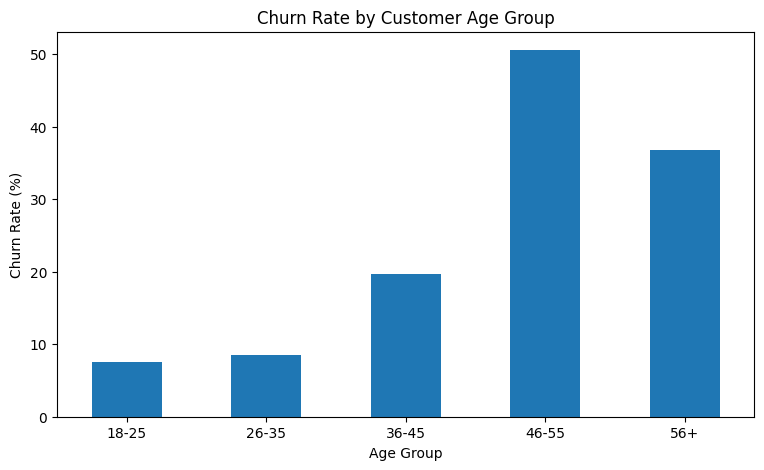

In [21]:
plt.figure(figsize=(9, 5))

age_churn.plot(kind="bar")

plt.title("Churn Rate by Customer Age Group")
plt.xlabel("Age Group")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [22]:
df["Geography"].value_counts()

Geography
France     5014
Germany    2509
Spain      2477
Name: count, dtype: int64

In [23]:
geo_churn = df.groupby("Geography")["Exited"].mean() * 100

print("Churn Rate by Geography:")
print(geo_churn.round(2))

Churn Rate by Geography:
Geography
France     16.15
Germany    32.44
Spain      16.67
Name: Exited, dtype: float64


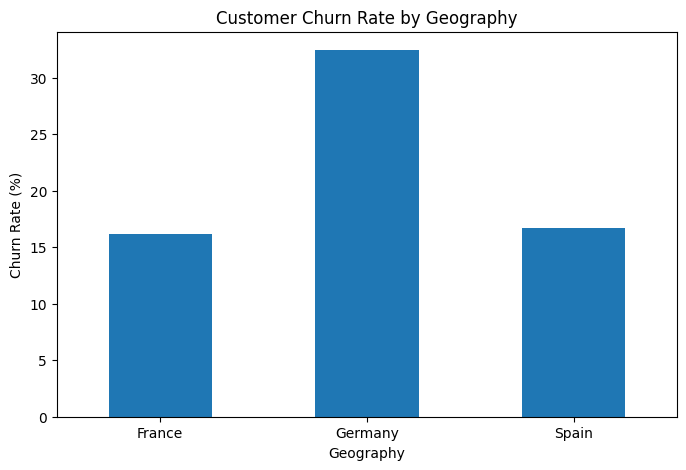

In [24]:
plt.figure(figsize=(8, 5))

geo_churn.plot(kind="bar")

plt.title("Customer Churn Rate by Geography")
plt.xlabel("Geography")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [25]:
# Count customers by gender

gender_counts = df["Gender"].value_counts()

print("Customers by Gender:")
print(gender_counts)

Customers by Gender:
Gender
Male      5457
Female    4543
Name: count, dtype: int64


In [26]:
# Calculate churn percentage by gender

gender_churn = df.groupby("Gender")["Exited"].mean() * 100

print("Churn Rate by Gender:")
print(gender_churn.round(2))

Churn Rate by Gender:
Gender
Female    25.07
Male      16.46
Name: Exited, dtype: float64


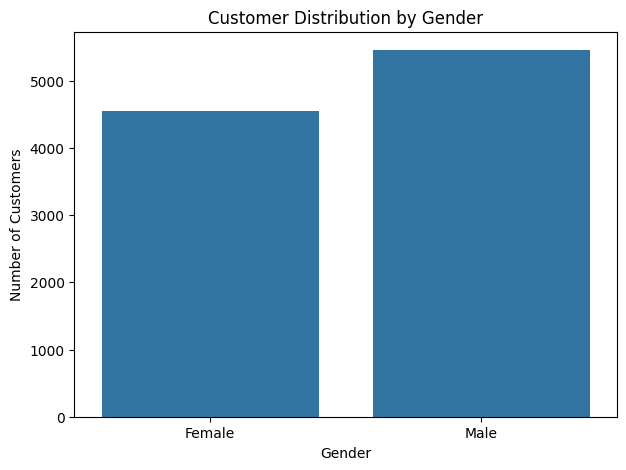

In [27]:
plt.figure(figsize=(7, 5))

sns.countplot(data=df, x="Gender")

plt.title("Customer Distribution by Gender")
plt.xlabel("Gender")
plt.ylabel("Number of Customers")

plt.show()

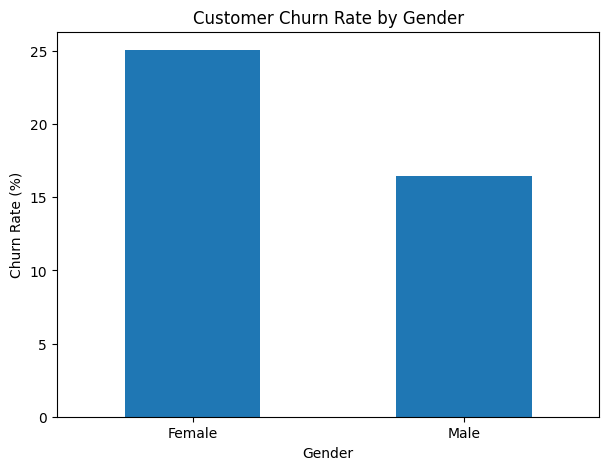

In [28]:
plt.figure(figsize=(7, 5))

gender_churn.plot(kind="bar")

plt.title("Customer Churn Rate by Gender")
plt.xlabel("Gender")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [29]:
print("Average Balance:", df["Balance"].mean())
print("Minimum Balance:", df["Balance"].min())
print("Maximum Balance:", df["Balance"].max())

Average Balance: 76485.889288
Minimum Balance: 0.0
Maximum Balance: 250898.09


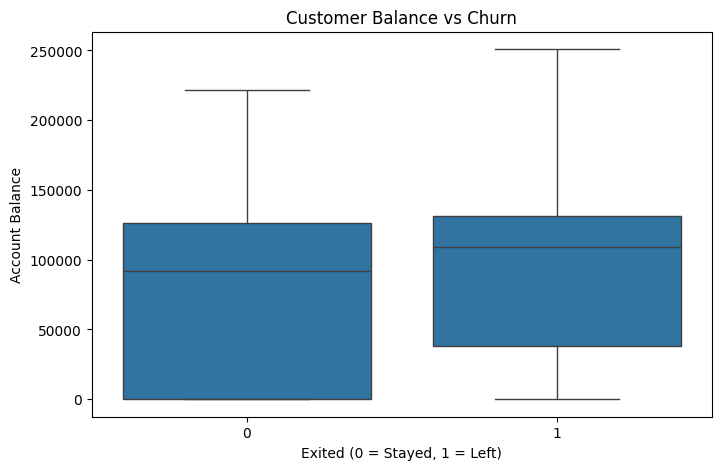

In [30]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Exited",
    y="Balance"
)

plt.title("Customer Balance vs Churn")
plt.xlabel("Exited (0 = Stayed, 1 = Left)")
plt.ylabel("Account Balance")

plt.show()

In [31]:
print("Average Balance:", df["Balance"].mean())
print("Median Balance:", df["Balance"].median())
print("Minimum Balance:", df["Balance"].min())
print("Maximum Balance:", df["Balance"].max())

Average Balance: 76485.889288
Median Balance: 97198.54000000001
Minimum Balance: 0.0
Maximum Balance: 250898.09


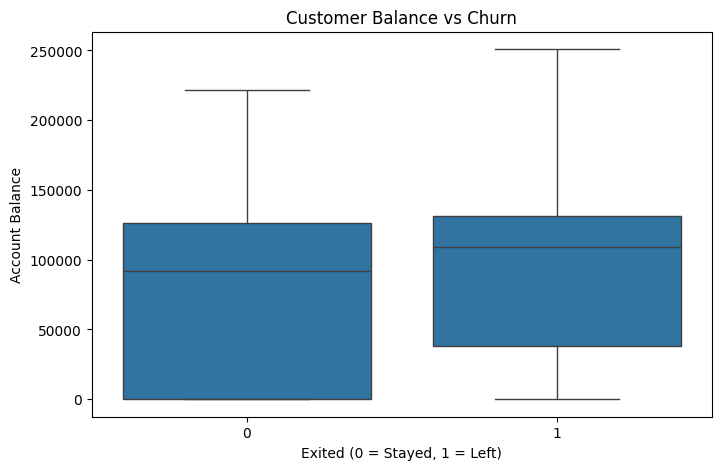

In [32]:
plt.figure(figsize=(8, 5))

sns.boxplot(
    data=df,
    x="Exited",
    y="Balance"
)

plt.title("Customer Balance vs Churn")
plt.xlabel("Exited (0 = Stayed, 1 = Left)")
plt.ylabel("Account Balance")

plt.show()

In [33]:
balance_analysis = df.groupby("Exited")["Balance"].mean()

print("Average Balance by Customer Status:")
print(balance_analysis)

Average Balance by Customer Status:
Exited
0    72745.296779
1    91108.539337
Name: Balance, dtype: float64


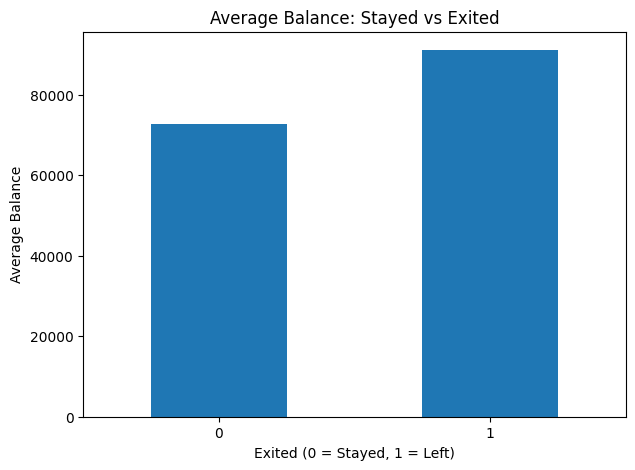

In [34]:
balance_analysis.plot(
    kind="bar",
    figsize=(7, 5)
)

plt.title("Average Balance: Stayed vs Exited")
plt.xlabel("Exited (0 = Stayed, 1 = Left)")
plt.ylabel("Average Balance")

plt.xticks(rotation=0)
plt.show()

In [35]:
active_churn = df.groupby("IsActiveMember")["Exited"].mean() * 100

print("Churn Rate by Active Membership:")
print(active_churn.round(2))

Churn Rate by Active Membership:
IsActiveMember
0    26.85
1    14.27
Name: Exited, dtype: float64


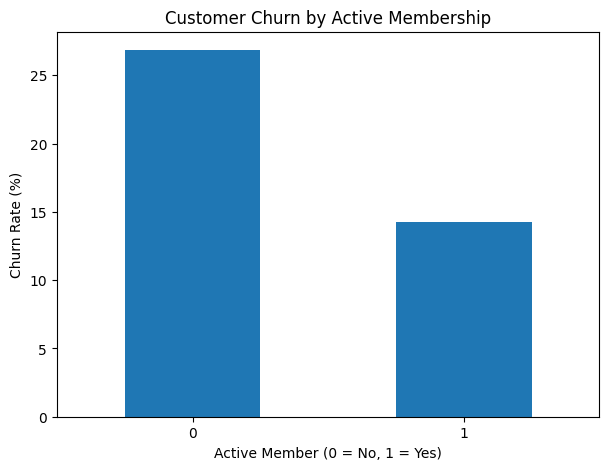

In [36]:
active_churn.plot(kind="bar", figsize=(7, 5))

plt.title("Customer Churn by Active Membership")
plt.xlabel("Active Member (0 = No, 1 = Yes)")
plt.ylabel("Churn Rate (%)")

plt.xticks(rotation=0)
plt.show()

In [38]:
active_churn = df.groupby("IsActiveMember")["Exited"].mean() * 100

print(active_churn.round(2))

IsActiveMember
0    26.85
1    14.27
Name: Exited, dtype: float64


In [39]:
product_counts = df["NumOfProducts"].value_counts().sort_index()

print("Customers by Number of Products:")
print(product_counts)

Customers by Number of Products:
NumOfProducts
1    5084
2    4590
3     266
4      60
Name: count, dtype: int64


In [40]:
product_churn = (
    df.groupby("NumOfProducts")["Exited"].mean() * 100
)

print("Churn Rate by Number of Products:")
print(product_churn.round(2))

Churn Rate by Number of Products:
NumOfProducts
1     27.71
2      7.58
3     82.71
4    100.00
Name: Exited, dtype: float64


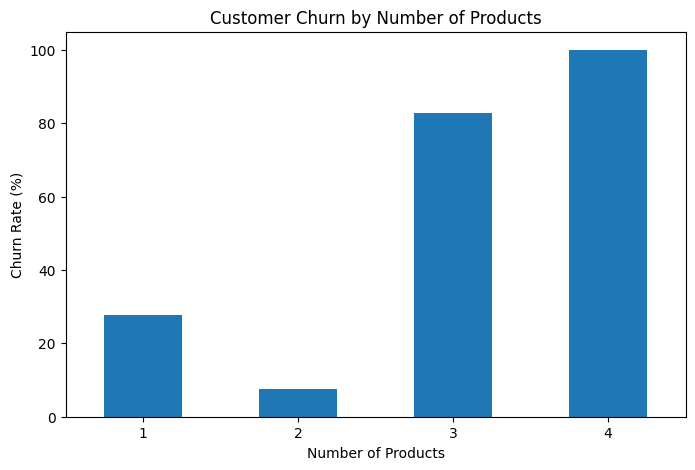

In [41]:
plt.figure(figsize=(8, 5))

product_churn.plot(kind="bar")

plt.title("Customer Churn by Number of Products")
plt.xlabel("Number of Products")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [42]:
print("Minimum Tenure:", df["Tenure"].min())
print("Maximum Tenure:", df["Tenure"].max())
print("Average Tenure:", df["Tenure"].mean())
print("Median Tenure:", df["Tenure"].median())

Minimum Tenure: 0
Maximum Tenure: 10
Average Tenure: 5.0128
Median Tenure: 5.0


In [43]:
tenure_counts = df["Tenure"].value_counts().sort_index()

print("Customers by Tenure:")
print(tenure_counts)

Customers by Tenure:
Tenure
0      413
1     1035
2     1048
3     1009
4      989
5     1012
6      967
7     1028
8     1025
9      984
10     490
Name: count, dtype: int64


In [44]:
tenure_churn = df.groupby("Tenure")["Exited"].mean() * 100

print("Churn Rate by Tenure:")
print(tenure_churn.round(2))

Churn Rate by Tenure:
Tenure
0     23.00
1     22.42
2     19.18
3     21.11
4     20.53
5     20.65
6     20.27
7     17.22
8     19.22
9     21.65
10    20.61
Name: Exited, dtype: float64


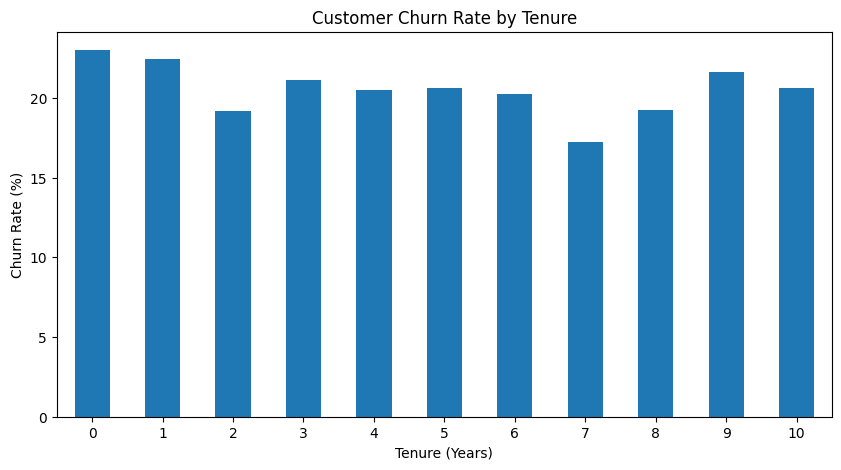

In [45]:
plt.figure(figsize=(10, 5))

tenure_churn.plot(kind="bar")

plt.title("Customer Churn Rate by Tenure")
plt.xlabel("Tenure (Years)")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [46]:
print(df["HasCrCard"].value_counts())

HasCrCard
1    7055
0    2945
Name: count, dtype: int64


In [47]:
creditcard_churn = df.groupby("HasCrCard")["Exited"].mean() * 100

print("Churn Rate by Credit Card Ownership:")
print(creditcard_churn.round(2))

Churn Rate by Credit Card Ownership:
HasCrCard
0    20.81
1    20.18
Name: Exited, dtype: float64


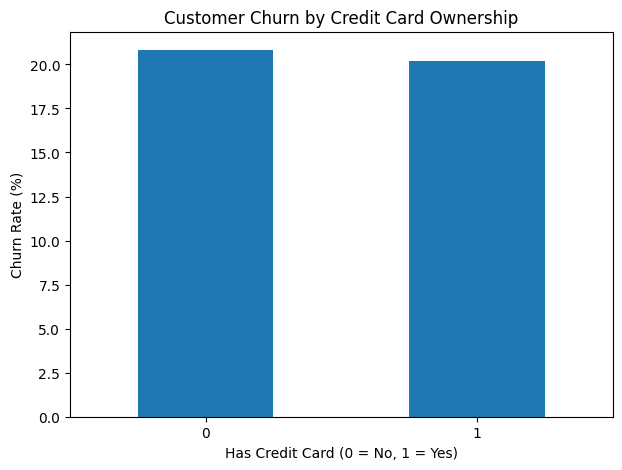

In [48]:
creditcard_churn.plot(kind="bar", figsize=(7, 5))

plt.title("Customer Churn by Credit Card Ownership")
plt.xlabel("Has Credit Card (0 = No, 1 = Yes)")
plt.ylabel("Churn Rate (%)")
plt.xticks(rotation=0)

plt.show()

In [49]:
# Select numerical columns
numeric_df = df.select_dtypes(include=["number"])

# Exclude customer identifiers
numeric_df = numeric_df.drop(
    columns=["RowNumber", "CustomerId"],
    errors="ignore"
)

print("Numerical Columns:")
print(numeric_df.columns.tolist())

Numerical Columns:
['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary', 'Exited']


In [50]:
correlation = numeric_df.corr()

print("Correlation with Customer Churn:")
print(
    correlation["Exited"]
    .sort_values(ascending=False)
    .round(3)
)

Correlation with Customer Churn:
Exited             1.000
Age                0.285
Balance            0.119
EstimatedSalary    0.012
HasCrCard         -0.007
Tenure            -0.014
CreditScore       -0.027
NumOfProducts     -0.048
IsActiveMember    -0.156
Name: Exited, dtype: float64


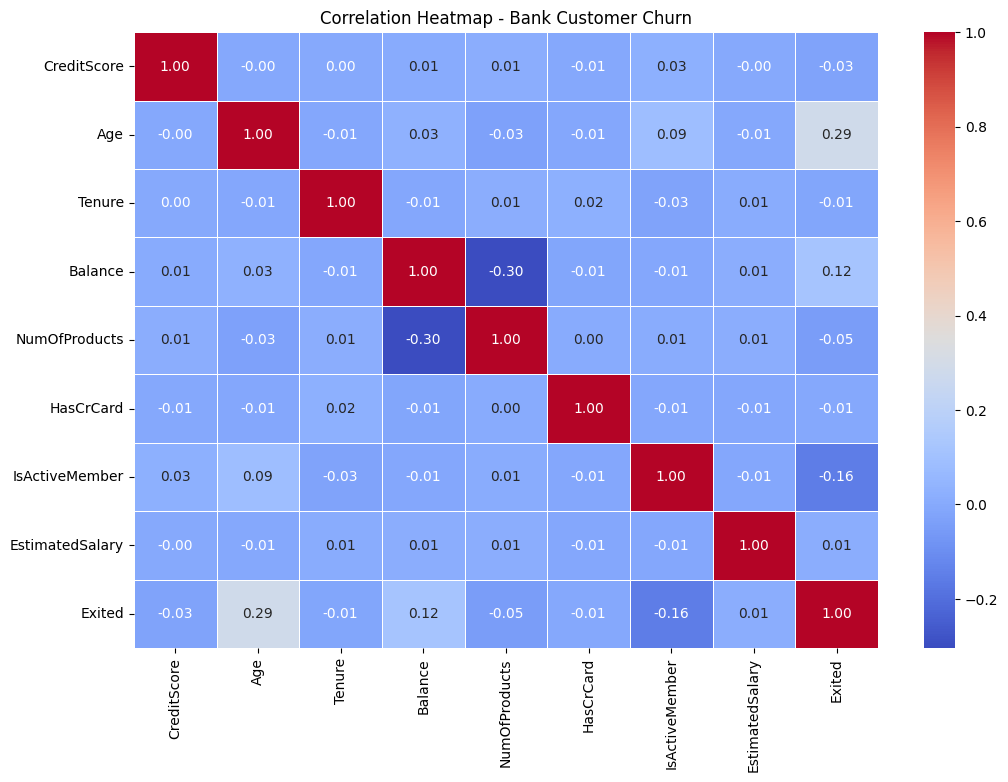

In [51]:
plt.figure(figsize=(12, 8))

sns.heatmap(
    correlation,
    annot=True,
    cmap="coolwarm",
    fmt=".2f",
    linewidths=0.5
)

plt.title("Correlation Heatmap - Bank Customer Churn")

plt.show()

In [52]:
print("BANK CUSTOMER CHURN - EDA SUMMARY")
print("----------------------------------")

print("Total Customers:", len(df))
print("Total Features:", df.shape[1])

print("Customers Exited:", (df["Exited"] == 1).sum())
print("Customers Stayed:", (df["Exited"] == 0).sum())

print("Missing Values:", df.isnull().sum().sum())
print("Duplicate Rows:", df.duplicated().sum())

BANK CUSTOMER CHURN - EDA SUMMARY
----------------------------------
Total Customers: 10000
Total Features: 14
Customers Exited: 2037
Customers Stayed: 7963
Missing Values: 0
Duplicate Rows: 0


In [53]:
# Create a separate feature dataset

X = df.drop(
    columns=["RowNumber", "CustomerId", "Surname", "Exited"]
)

# Target variable
y = df["Exited"]

print("Features shape:", X.shape)
print("Target shape:", y.shape)

Features shape: (10000, 10)
Target shape: (10000,)


In [54]:
categorical_features = ["Geography", "Gender"]

numerical_features = [
    "CreditScore",
    "Age",
    "Tenure",
    "Balance",
    "NumOfProducts",
    "HasCrCard",
    "IsActiveMember",
    "EstimatedSalary"
]

print("Categorical Features:")
print(categorical_features)

print("\nNumerical Features:")
print(numerical_features)

Categorical Features:
['Geography', 'Gender']

Numerical Features:
['CreditScore', 'Age', 'Tenure', 'Balance', 'NumOfProducts', 'HasCrCard', 'IsActiveMember', 'EstimatedSalary']


In [55]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.20,
    random_state=42,
    stratify=y
)

print("Training Features:", X_train.shape)
print("Testing Features:", X_test.shape)

print("Training Target:", y_train.shape)
print("Testing Target:", y_test.shape)

Training Features: (8000, 10)
Testing Features: (2000, 10)
Training Target: (8000,)
Testing Target: (2000,)


In [56]:
from sklearn.preprocessing import StandardScaler, OneHotEncoder
from sklearn.compose import ColumnTransformer

preprocessor = ColumnTransformer(
    transformers=[
        (
            "num",
            StandardScaler(),
            numerical_features
        ),
        (
            "cat",
            OneHotEncoder(handle_unknown="ignore"),
            categorical_features
        )
    ]
)

print("Preprocessor created successfully!")

Preprocessor created successfully!


In [57]:
# Fit preprocessing on training data
X_train_processed = preprocessor.fit_transform(X_train)

# Transform testing data using the same fitted preprocessor
X_test_processed = preprocessor.transform(X_test)

print("Training data shape:", X_train_processed.shape)
print("Testing data shape:", X_test_processed.shape)

Training data shape: (8000, 13)
Testing data shape: (2000, 13)


In [58]:
from sklearn.linear_model import LogisticRegression

# Create model
lr_model = LogisticRegression(
    max_iter=1000,
    random_state=42
)

# Train model
lr_model.fit(X_train_processed, y_train)

print("Logistic Regression training completed!")

Logistic Regression training completed!


In [59]:
# Predict customer churn
y_pred_lr = lr_model.predict(X_test_processed)

# Predict churn probabilities
y_prob_lr = lr_model.predict_proba(X_test_processed)[:, 1]

print("First 10 predictions:")
print(y_pred_lr[:10])

First 10 predictions:
[0 0 0 0 0 0 0 0 0 0]


In [60]:
from sklearn.metrics import (
    accuracy_score,
    precision_score,
    recall_score,
    f1_score,
    roc_auc_score
)

print("LOGISTIC REGRESSION PERFORMANCE")
print("--------------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_lr))
print("Precision:", precision_score(y_test, y_pred_lr))
print("Recall:", recall_score(y_test, y_pred_lr))
print("F1 Score:", f1_score(y_test, y_pred_lr))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_lr))

LOGISTIC REGRESSION PERFORMANCE
--------------------------------
Accuracy: 0.808
Precision: 0.5891472868217055
Recall: 0.18673218673218672
F1 Score: 0.2835820895522388
ROC-AUC: 0.7747578086561138


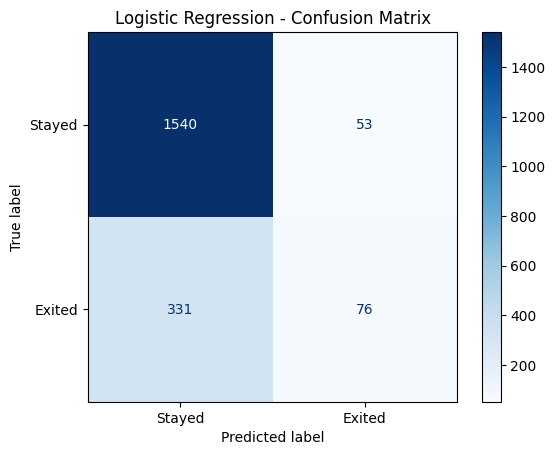

In [61]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_lr)

display = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Exited"]
)

display.plot(cmap="Blues")

plt.title("Logistic Regression - Confusion Matrix")
plt.show()

In [62]:
from sklearn.tree import DecisionTreeClassifier

dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42,
    class_weight="balanced"
)

dt_model.fit(X_train_processed, y_train)

print("Decision Tree training completed!")

Decision Tree training completed!


In [63]:
y_pred_dt = dt_model.predict(X_test_processed)

y_prob_dt = dt_model.predict_proba(X_test_processed)[:, 1]

print("First 10 predictions:")
print(y_pred_dt[:10])

First 10 predictions:
[0 0 0 0 0 1 0 1 1 0]


In [64]:
print("DECISION TREE PERFORMANCE")
print("--------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_dt))
print("Precision:", precision_score(y_test, y_pred_dt))
print("Recall:", recall_score(y_test, y_pred_dt))
print("F1 Score:", f1_score(y_test, y_pred_dt))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_dt))

DECISION TREE PERFORMANCE
--------------------------
Accuracy: 0.7705
Precision: 0.46153846153846156
Recall: 0.7665847665847666
F1 Score: 0.5761772853185596
ROC-AUC: 0.8402863572355097


In [65]:
from sklearn.ensemble import RandomForestClassifier

rf_model = RandomForestClassifier(
    n_estimators=200,
    max_depth=12,
    min_samples_split=5,
    random_state=42,
    class_weight="balanced",
    n_jobs=-1
)

rf_model.fit(X_train_processed, y_train)

print("Random Forest training completed!")

Random Forest training completed!


In [66]:
y_pred_rf = rf_model.predict(X_test_processed)

y_prob_rf = rf_model.predict_proba(X_test_processed)[:, 1]

print("First 10 predictions:")
print(y_pred_rf[:10])

First 10 predictions:
[0 0 0 0 0 0 0 0 1 0]


In [67]:
print("RANDOM FOREST PERFORMANCE")
print("-------------------------")

print("Accuracy:", accuracy_score(y_test, y_pred_rf))
print("Precision:", precision_score(y_test, y_pred_rf))
print("Recall:", recall_score(y_test, y_pred_rf))
print("F1 Score:", f1_score(y_test, y_pred_rf))
print("ROC-AUC:", roc_auc_score(y_test, y_prob_rf))

RANDOM FOREST PERFORMANCE
-------------------------
Accuracy: 0.851
Precision: 0.6476964769647696
Recall: 0.5872235872235873
F1 Score: 0.615979381443299
ROC-AUC: 0.8583668414176888


In [68]:
results = pd.DataFrame({
    "Model": [
        "Logistic Regression",
        "Decision Tree",
        "Random Forest"
    ],
    "Accuracy": [
        accuracy_score(y_test, y_pred_lr),
        accuracy_score(y_test, y_pred_dt),
        accuracy_score(y_test, y_pred_rf)
    ],
    "Precision": [
        precision_score(y_test, y_pred_lr),
        precision_score(y_test, y_pred_dt),
        precision_score(y_test, y_pred_rf)
    ],
    "Recall": [
        recall_score(y_test, y_pred_lr),
        recall_score(y_test, y_pred_dt),
        recall_score(y_test, y_pred_rf)
    ],
    "F1 Score": [
        f1_score(y_test, y_pred_lr),
        f1_score(y_test, y_pred_dt),
        f1_score(y_test, y_pred_rf)
    ],
    "ROC-AUC": [
        roc_auc_score(y_test, y_prob_lr),
        roc_auc_score(y_test, y_prob_dt),
        roc_auc_score(y_test, y_prob_rf)
    ]
})

results.round(3)

,Model,Accuracy,Precision,Recall,F1 Score,ROC-AUC
0,Logistic Regression,0.808,0.589,0.187,0.284,0.775
1,Decision Tree,0.770,0.462,0.767,0.576,0.840
2,Random Forest,0.851,0.648,0.587,0.616,0.858


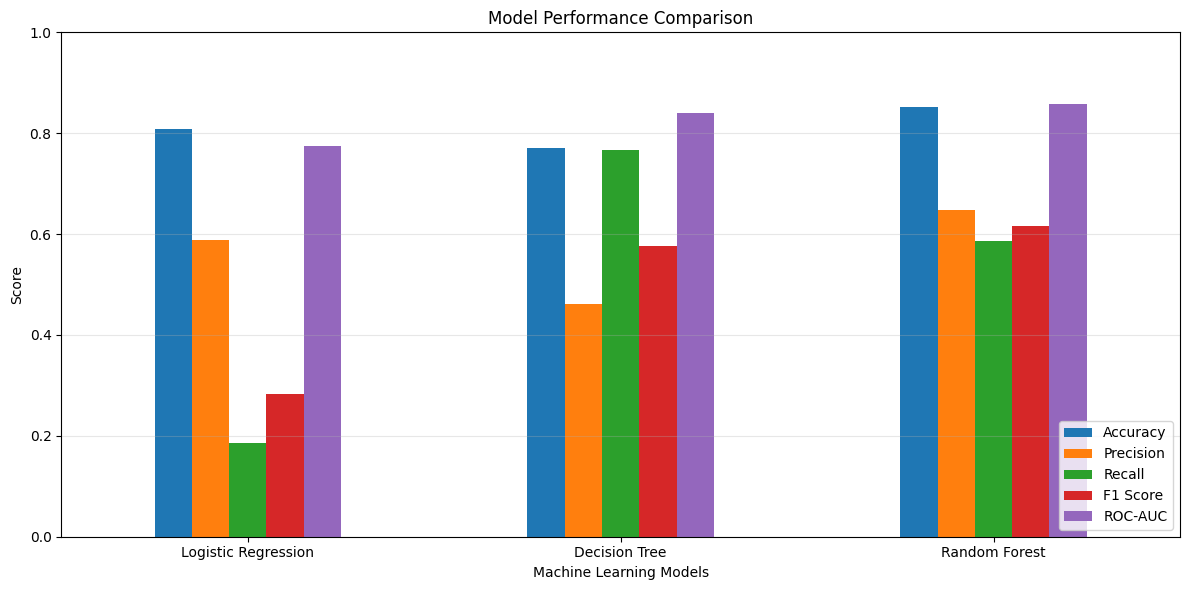

In [69]:
metrics = ["Accuracy", "Precision", "Recall", "F1 Score", "ROC-AUC"]

results_plot = results.set_index("Model")[metrics]

results_plot.plot(
    kind="bar",
    figsize=(12, 6)
)

plt.title("Model Performance Comparison")
plt.ylabel("Score")
plt.xlabel("Machine Learning Models")
plt.ylim(0, 1)
plt.xticks(rotation=0)
plt.legend(loc="lower right")
plt.grid(axis="y", alpha=0.3)
plt.tight_layout()
plt.show()

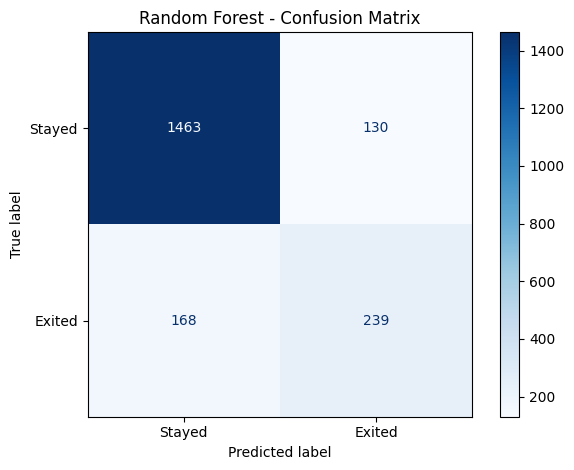

In [70]:
from sklearn.metrics import confusion_matrix, ConfusionMatrixDisplay

cm = confusion_matrix(y_test, y_pred_rf)

disp = ConfusionMatrixDisplay(
    confusion_matrix=cm,
    display_labels=["Stayed", "Exited"]
)

disp.plot(cmap="Blues", values_format="d")

plt.title("Random Forest - Confusion Matrix")
plt.tight_layout()
plt.show()

In [71]:
from sklearn.pipeline import Pipeline
from sklearn.ensemble import RandomForestClassifier
import joblib
from pathlib import Path

# Create the complete ML pipeline
final_pipeline = Pipeline([
    ("preprocessor", preprocessor),
    ("classifier", RandomForestClassifier(
        n_estimators=200,
        max_depth=12,
        min_samples_split=5,
        random_state=42,
        class_weight="balanced",
        n_jobs=-1
    ))
])

# Train using the original, unprocessed training data
final_pipeline.fit(X_train, y_train)

print("Final pipeline trained successfully!")

Final pipeline trained successfully!


In [72]:
# Create models folder if it doesn't exist
Path("models").mkdir(exist_ok=True)

# Save the complete pipeline
joblib.dump(
    final_pipeline,
    "models/bank_churn_pipeline.pkl"
)

print("Model saved successfully!")

Model saved successfully!


In [73]:
from pathlib import Path

model_path = Path("models/bank_churn_pipeline.pkl")

print("Current working directory:", Path.cwd())
print("Model exists:", model_path.exists())
print("Model location:", model_path.resolve())

Current working directory: c:\Users\navya\Documents\Bank-Customer-Churn\notebooks
Model exists: True
Model location: C:\Users\navya\Documents\Bank-Customer-Churn\notebooks\models\bank_churn_pipeline.pkl


In [74]:
from pathlib import Path
import shutil

# Source: model currently inside notebooks/models
source = Path("models/bank_churn_pipeline.pkl")

# Destination: main project/models folder
destination = Path("../models/bank_churn_pipeline.pkl")

destination.parent.mkdir(exist_ok=True)

shutil.move(str(source), str(destination))

print("Model moved successfully!")
print("New location:", destination.resolve())

Model moved successfully!
New location: C:\Users\navya\Documents\Bank-Customer-Churn\models\bank_churn_pipeline.pkl


In [75]:
model_path = Path("../models/bank_churn_pipeline.pkl")

print("Model exists:", model_path.exists())
print("Model location:", model_path.resolve())

Model exists: True
Model location: C:\Users\navya\Documents\Bank-Customer-Churn\models\bank_churn_pipeline.pkl


In [76]:
import joblib
import pandas as pd

# Load the saved pipeline
loaded_model = joblib.load("../models/bank_churn_pipeline.pkl")

# Sample customer details
sample_customer = pd.DataFrame([{
    "CreditScore": 650,
    "Geography": "France",
    "Gender": "Female",
    "Age": 40,
    "Tenure": 5,
    "Balance": 75000,
    "NumOfProducts": 2,
    "HasCrCard": 1,
    "IsActiveMember": 1,
    "EstimatedSalary": 60000
}])

# Make prediction
prediction = loaded_model.predict(sample_customer)[0]
probability = loaded_model.predict_proba(sample_customer)[0][1]

print("Prediction:", "Exited" if prediction == 1 else "Stayed")
print("Churn Probability:", round(probability * 100, 2), "%")

Prediction: Stayed
Churn Probability: 18.22 %
